# Feature engineering — Icentia11k e PhysioNet 2017

Exploração dos **datasets já preparados**, para medir se features candidatas acrescentam informação a um conjunto de base. Os datasets são analisados **separadamente**: Icentia classifica batimentos N/S/V/Q; PhysioNet classifica registos N/A/O/~.

Este notebook não modifica os sinais nem as partições existentes. **Na análise e seleção (Etapas 1 e 2), test não é carregado nem usado para escolher features.** A seleção é feita por validação cruzada dentro de train; dev compara uma única escolha com a base. No Icentia a validação cruzada mantém cada paciente num único fold.

A execução inicial é uma experiência piloto: amostra aleatória limitada por paciente e classe no Icentia, e todos os registos train/dev no PhysioNet. A amostragem usa labels e altera as prevalências: métricas do piloto não estimam o desempenho na distribuição completa. Para confirmar conclusões, repetir com a distribuição natural de train/dev e, só após fixar as decisões, avaliar test uma vez.

A secção final materializa os datasets com as features já fixadas, incluindo test, sem usar test para seleção, ajuste de transformações ou métricas.


In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sp_signal
from scipy.stats import skew, kurtosis
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report
from sklearn.exceptions import ConvergenceWarning

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "requirements.txt").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "datasets").is_dir():
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")
ICENTIA_ROOT = PROJECT_ROOT / "datasets" / "icentia11_prepared"
PHYSIO_ROOT = PROJECT_ROOT / "datasets" / "physionet2017_prepared_normalized"
if not PHYSIO_ROOT.is_dir():
    PHYSIO_ROOT = PROJECT_ROOT / "DataPreparation" / "physionet2017_prepared_normalized"
OUTPUT_ROOT = PROJECT_ROOT / "datasets" / "feature_engineering"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SEED = 2024
MAX_ICENTIA_PER_PATIENT_CLASS = 250  # None: todos os batimentos train/dev; execução muito mais demorada.
N_FOLDS = 4
FS = 200
LABELS = {"icentia11k": ["N", "S", "V", "Q"], "physionet2017": ["N", "A", "O", "~"]}
for directory in (ICENTIA_ROOT, PHYSIO_ROOT):
    if not (directory / "manifest.csv").is_file():
        raise FileNotFoundError(f"Manifesto preparado em falta: {directory}")
print("Icentia:", ICENTIA_ROOT)
print("PhysioNet:", PHYSIO_ROOT)
print("Resultados locais:", OUTPUT_ROOT)


Icentia: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/datasets/icentia11_prepared
PhysioNet: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/datasets/physionet2017_prepared_normalized
Resultados locais: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/datasets/feature_engineering


## Definição das features

| Grupo | Features | Observações |
| --- | --- | --- |
| Base | média, desvio-padrão, pico a pico, RMS, IQR | Algumas são quase constantes após normalização; isso será medido em train. |
| Forma | assimetria, curtose, diferença absoluta média, máximo da derivada aproximada, variação total por segundo | Estatísticas exploratórias, sem diagnóstico clínico. |
| Frequência | entropia espectral, frequência dominante e frações de potência 0,5–5 / 5–15 / 15–40 Hz | Welch; interpretação limitada em janelas de apenas 1 s. |
| Amplitude original | pico a pico e máximo absoluto anteriores à normalização | Apenas Icentia, a partir do manifesto existente. Não se recupera amplitude absoluta dos sinais normalizados. |
| RR aproximado | mediana e IQR dos RR, RMSSD, número de intervalos | Apenas PhysioNet. Detetor heurístico exploratório, sem validar os picos contra anotações clínicas. |

Os 500 pontos do Icentia representam **1 segundo interpolado de 200 amostras**, não 2,5 s a 200 Hz. Para as features de frequência/derivada, reconstruímos uma grelha de 200 pontos sobre o mesmo intervalo. No PhysioNet removemos apenas o padding à direita, usando o comprimento do header original e a razão de reamostragem; não inferimos padding procurando zeros no ECG. Não calculamos HRV a partir de batimentos isolados.

In [2]:
BASE_FEATURES = ["mean", "std", "peak_to_peak", "rms", "iqr"]
SHAPE_FEATURES = ["skewness", "kurtosis", "mean_abs_difference", "max_abs_slope", "total_variation_per_second"]
SPECTRAL_FEATURES = ["spectral_entropy", "dominant_frequency_hz", "power_fraction_0_5_5", "power_fraction_5_15", "power_fraction_15_40"]
AMPLITUDE_FEATURES = ["source_peak_to_peak", "source_max_abs"]
RR_FEATURES = ["rr_median_ms", "rr_iqr_ms", "rr_rmssd_ms", "rr_interval_count"]

def extract_features(values, fs=FS, include_rr=False):
    x = np.asarray(values, dtype=np.float64).reshape(-1)
    if x.size < 4 or not np.isfinite(x).all():
        raise ValueError("Sinal demasiado curto ou com valores não finitos.")
    std = float(x.std())
    diff = np.diff(x)
    out = {
        "mean": float(x.mean()), "std": std, "peak_to_peak": float(np.ptp(x)),
        "rms": float(np.sqrt(np.mean(x*x))), "iqr": float(np.quantile(x, .75)-np.quantile(x, .25)),
        "skewness": float(skew(x)) if std > 1e-12 else np.nan,
        "kurtosis": float(kurtosis(x, fisher=False)) if std > 1e-12 else np.nan,
        "mean_abs_difference": float(np.mean(np.abs(diff))),
        "max_abs_slope": float(np.max(np.abs(diff))*fs),
        "total_variation_per_second": float(np.sum(np.abs(diff))/(len(diff)/fs)),
    }
    frequencies, psd = sp_signal.welch(x, fs=fs, nperseg=min(256, len(x)), detrend="constant")
    valid = (frequencies >= .5) & (frequencies <= 40)
    f, power = frequencies[valid], psd[valid]
    total = float(power.sum())
    if total > np.finfo(float).eps and len(power) > 1:
        probabilities = power / total
        positive = probabilities[probabilities > 0]
        out["spectral_entropy"] = float(-np.sum(positive*np.log(positive))/np.log(len(power)))
        out["dominant_frequency_hz"] = float(f[np.argmax(power)])
        for name, low, high in [("0_5_5", .5, 5), ("5_15", 5, 15), ("15_40", 15, 40.0001)]:
            out[f"power_fraction_{name}"] = float(power[(f >= low) & (f < high)].sum()/total)
    else:
        out.update({name: np.nan for name in SPECTRAL_FEATURES})
    if include_rr:
        # Detetor simples: filtragem 5–20 Hz, retificação e proeminência relativa.
        # Picos próximos de ondas T/artefactos podem persistir; são features candidatas.
        filtered = sp_signal.sosfiltfilt(sp_signal.butter(3, [5, 20], fs=fs, btype="bandpass", output="sos"), x)
        envelope = np.abs(filtered)
        peaks, _ = sp_signal.find_peaks(envelope, distance=int(.3*fs), prominence=max(.5*envelope.std(), 1e-9))
        rr = np.diff(peaks)/fs*1000
        out.update({
            "rr_median_ms": float(np.median(rr)) if len(rr) else np.nan,
            "rr_iqr_ms": float(np.quantile(rr,.75)-np.quantile(rr,.25)) if len(rr) else np.nan,
            "rr_rmssd_ms": float(np.sqrt(np.mean(np.diff(rr)**2))) if len(rr) > 1 else np.nan,
            "rr_interval_count": float(len(rr)),
        })
    return out


## Amostragem e leitura

A amostragem do Icentia é aleatória e reproduzível dentro de cada paciente/classe, sem carregar milhões de sinais em memória. Todos os batimentos de classes com menos de 250 exemplos por paciente são mantidos. A amostra mantém os splits existentes, mas a distribuição fica diferente da original.

No PhysioNet cada exemplo continua a ser um registo. Os clientes são simulados e não demonstram identidade de paciente; não podemos garantir disjunção por paciente nesse dataset.

In [3]:
def select_icentia_rows(limit=MAX_ICENTIA_PER_PATIENT_CLASS):
    rng = np.random.default_rng(SEED)
    selected = {}
    required = ["patient_id", "record_id", "split", "client_id", "label", "segment_path", "raw_peak_to_peak", "raw_max_abs", "n_samples"]
    for chunk in pd.read_csv(ICENTIA_ROOT / "manifest.csv", usecols=required, dtype={"client_id": "string"}, chunksize=150000):
        chunk = chunk[chunk["split"].isin(["train", "dev"])].copy()
        chunk["_random_priority"] = rng.random(len(chunk))
        for key, part in chunk.groupby(["patient_id", "label"], sort=False):
            combined = pd.concat([selected[key], part], ignore_index=True) if key in selected else part
            selected[key] = combined.nsmallest(limit, "_random_priority") if limit is not None else combined
    rows = pd.concat(list(selected.values()), ignore_index=True).drop(columns="_random_priority")
    assert rows["segment_path"].is_unique and not rows["split"].eq("test").any()
    assert rows.groupby("patient_id")["split"].nunique().eq(1).all()
    return rows.sort_values(["split", "patient_id", "record_id", "segment_path"]).reset_index(drop=True)

icentia_selection = select_icentia_rows()
physio_manifest = pd.read_csv(PHYSIO_ROOT / "manifest.csv")
physio_selection = physio_manifest[physio_manifest["split"].isin(["train", "dev"])].copy()
assert physio_selection["record"].is_unique
print("Icentia: batimentos selecionados (amostragem limitada por paciente/classe)")
display(pd.crosstab(icentia_selection["split"], icentia_selection["label"]).reindex(columns=LABELS["icentia11k"], fill_value=0))
print("PhysioNet: registos selecionados")
display(pd.crosstab(physio_selection["split"], physio_selection["label"]).reindex(columns=LABELS["physionet2017"], fill_value=0))


label,N,S,V,Q
split,,,,
dev,500,252,12,500
train,4000,1087,1340,4000


label,N,A,O,~
split,,,,
dev,631,92,307,35
train,3788,554,1842,214


Icentia: batimentos selecionados (amostragem limitada por paciente/classe)
PhysioNet: registos selecionados


In [4]:
def extract_icentia(rows):
    records = []
    for row in rows.itertuples(index=False):
        with np.load(ICENTIA_ROOT / row.segment_path, allow_pickle=False) as data:
            beat = data["signal"]
            if beat.shape != (500,) or str(data["label"]) != row.label:
                raise ValueError(f"Batimento incompatível com manifesto: {row.segment_path}")
            # Inversão aproximada da interpolação linear definida na preparação.
            x = np.interp(np.linspace(0, 1, FS), np.linspace(0, 1, len(beat)), beat)
        features = extract_features(x)
        features.update({"source_peak_to_peak": row.raw_peak_to_peak, "source_max_abs": row.raw_max_abs})
        records.append({"sample_id": row.segment_path, "group_id": row.patient_id,
                        "client_id": row.client_id, "split": row.split, "label": row.label, **features})
    return pd.DataFrame(records)

def extract_physio(rows):
    records = []
    for client, client_rows in rows.groupby("client", sort=True):
        # Só abre os NPZ de train/dev. O cliente test nunca é carregado.
        with np.load(PHYSIO_ROOT / f"{client}.npz", allow_pickle=False) as data:
            lookup = {str(record): index for index, record in enumerate(data["record_ids"])}
            X = data["X"]
            stored_labels = data["labels"]
            for row in client_rows.itertuples(index=False):
                index = lookup[row.record]
                assert str(stored_labels[index]) == row.label
                header = (PROJECT_ROOT / "datasets" / "training2017" / f"{row.record}.hea").read_text().splitlines()[0].split()
                source_fs, source_samples = float(header[2]), int(header[3])
                real_samples = min(X.shape[1], int(np.ceil(source_samples * FS/source_fs)))
                x = X[index, :real_samples]
                records.append({"sample_id": row.record, "group_id": row.record,
                                "client_id": client, "split": row.split, "label": row.label,
                                **extract_features(x, include_rr=True)})
    return pd.DataFrame(records)

features = {"icentia11k": extract_icentia(icentia_selection), "physionet2017": extract_physio(physio_selection)}
for name, frame in features.items():
    assert frame["sample_id"].is_unique and not frame["split"].eq("test").any()
    assert set(frame["label"]).issubset(LABELS[name])
    frame.to_csv(OUTPUT_ROOT / f"{name}_train_dev_features.csv", index=False)
    print(name, frame.shape)


icentia11k (11691, 22)
physionet2017 (7463, 24)


## Qualidade, redundância e distribuição das features

A análise abaixo usa apenas train. Features quase constantes, muitos valores em falta ou correlações muito elevadas podem não acrescentar informação. Não são eliminadas manualmente a partir de dev/test: imputação, remoção de constantes e normalização são ajustadas dentro de cada fold de treino.

IDs de paciente/cliente/registo, labels, posições das anotações e erros de alinhamento nunca entram no modelo. A qualidade SQI também não entra nesta primeira comparação: aqui estamos a testar features novas do sinal e amplitude original, sem confundir a label clínica com qualidade.

,missing_fraction,std_train,unique_values_train,near_constant_train
mean,0.0,0.170134,10427,False
std,0.0,0.032084,10427,False
peak_to_peak,0.0,0.006139,10427,False
rms,0.0,0.157838,10427,False
iqr,0.0,0.067440,10427,False
skewness,0.0,1.756077,10427,False
kurtosis,0.0,5.403355,10427,False
mean_abs_difference,0.0,0.011522,10427,False
max_abs_slope,0.0,12.966318,10427,False
total_variation_per_second,0.0,2.304332,10427,False


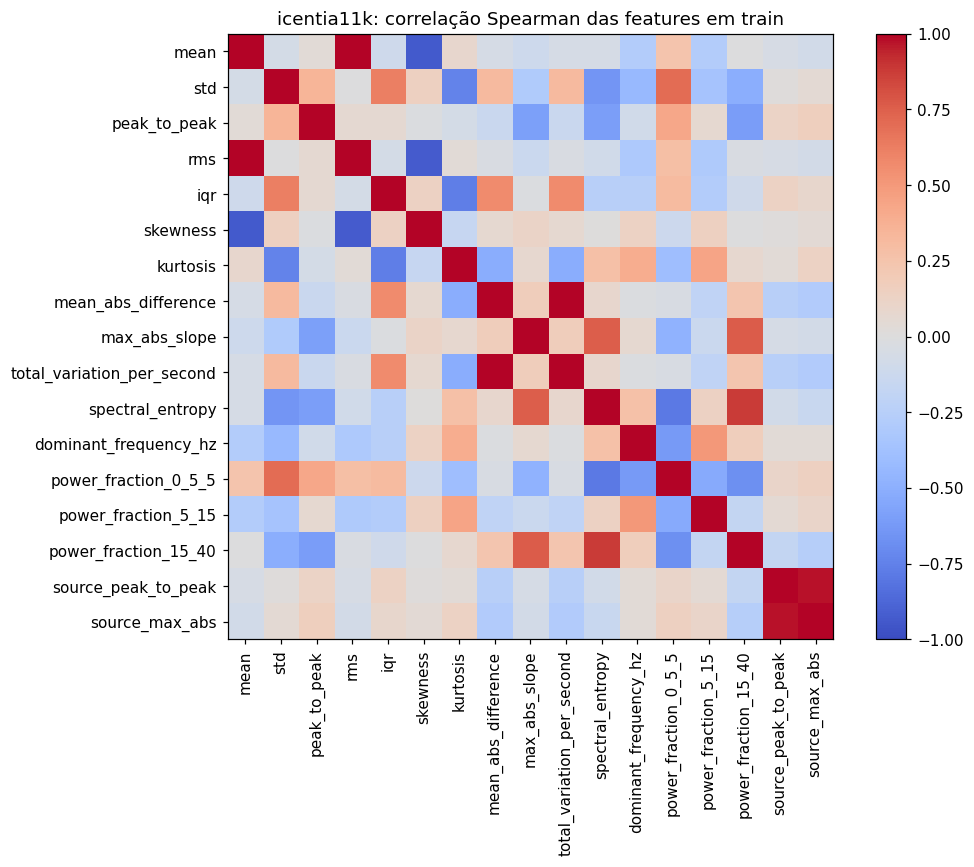

,missing_fraction,std_train,unique_values_train,near_constant_train
mean,0.0,3.425618e-10,6386,True
std,0.0,1.369003e-09,6397,True
peak_to_peak,0.0,3.095223e+00,6397,False
rms,0.0,1.369003e-09,6397,True
iqr,0.0,2.231941e-01,6397,False
skewness,0.0,2.271618e+00,6397,False
kurtosis,0.0,1.582343e+01,6397,False
mean_abs_difference,0.0,3.244581e-02,6397,False
max_abs_slope,0.0,1.840066e+02,6397,False
total_variation_per_second,0.0,6.489162e+00,6397,False


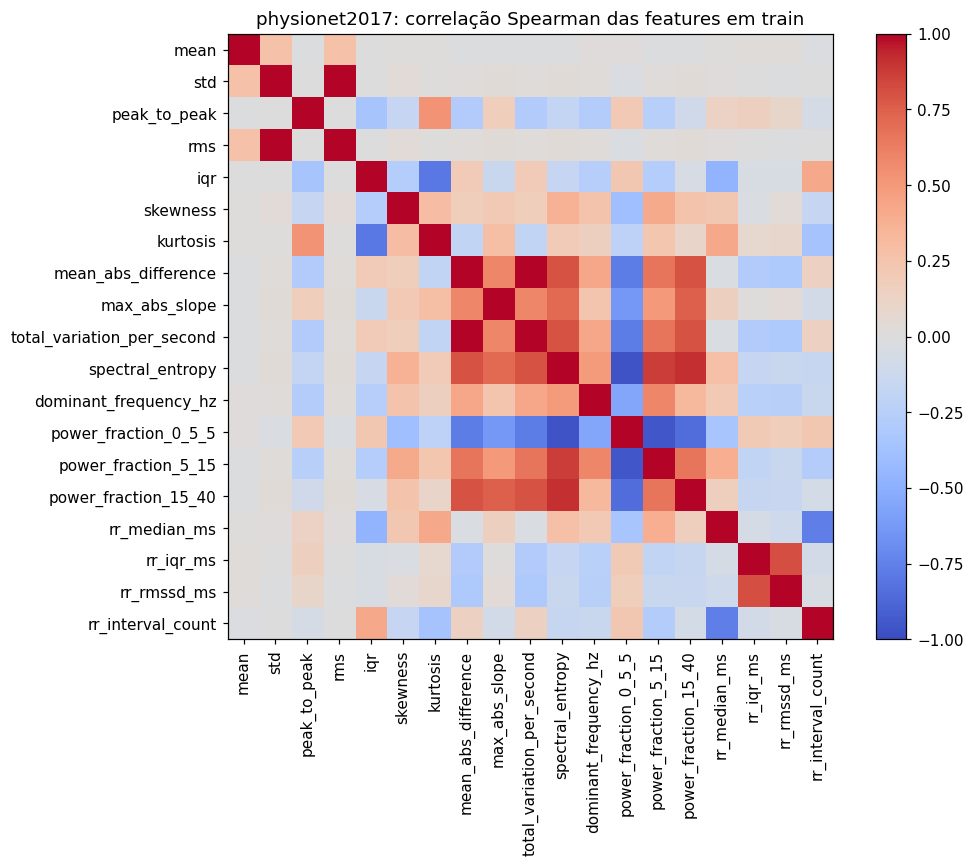

icentia11k — qualidade em train
physionet2017 — qualidade em train


In [5]:
FEATURE_GROUPS = {
    "icentia11k": {"forma": SHAPE_FEATURES, "frequencia": SPECTRAL_FEATURES, "amplitude_original": AMPLITUDE_FEATURES},
    "physionet2017": {"forma": SHAPE_FEATURES, "frequencia": SPECTRAL_FEATURES, "rr_aproximado": RR_FEATURES},
}
feature_quality = {}
for name, frame in features.items():
    columns = BASE_FEATURES + [f for group in FEATURE_GROUPS[name].values() for f in group]
    train = frame.loc[frame["split"].eq("train"), columns].replace([np.inf, -np.inf], np.nan)
    quality = pd.DataFrame({"missing_fraction": train.isna().mean(), "std_train": train.std(), "unique_values_train": train.nunique()})
    quality["near_constant_train"] = quality["std_train"].fillna(0) < 1e-6
    feature_quality[name] = quality
    quality.to_csv(OUTPUT_ROOT / f"{name}_feature_quality.csv")
    print(name, "— qualidade em train")
    display(quality)
    corr = train.corr(method="spearman")
    fig, ax = plt.subplots(figsize=(10, 8))
    plot = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(columns)), columns, rotation=90)
    ax.set_yticks(range(len(columns)), columns)
    ax.set_title(f"{name}: correlação Spearman das features em train")
    fig.colorbar(plot, ax=ax)
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"{name}_feature_correlation.png", dpi=140)
    plt.show()
    plt.close(fig)


## Comparação por adição de grupos de features

Comparamos a base, a base com cada grupo candidato e a base com todos os grupos. O classificador é o mesmo em todas as variantes: regressão logística com pesos de classe, imputação, remoção de features com variância ≤ 1e-12 e padronização ajustadas só no treino de cada fold.

A seleção é pelo F1 macro médio nos folds de train, sem consultar dev. Também reportamos desvio-padrão entre folds e balanced accuracy. O desvio entre folds não é um intervalo de confiança. Ganhos pequenos ou instáveis não são prova suficiente para adicionar features; este modelo linear também pode não captar interações úteis para outros modelos.

In [6]:
def build_model():
    return make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        VarianceThreshold(threshold=1e-12), StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1500, random_state=SEED),
    )

def feature_sets(name):
    groups = FEATURE_GROUPS[name]
    return {"base": BASE_FEATURES,
            **{f"base+{group}": BASE_FEATURES + columns for group, columns in groups.items()},
            "base+todas": list(dict.fromkeys(BASE_FEATURES + [f for columns in groups.values() for f in columns]))}

comparison_rows, fold_rows, fold_assignments = [], [], []
for name, frame in features.items():
    train = frame.loc[frame["split"].eq("train")].reset_index(drop=True)
    y = train["label"].to_numpy()
    if name == "icentia11k":
        splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
        folds = list(splitter.split(train, y, groups=train["group_id"]))
        for fit_indices, validation_indices in folds:
            assert not set(train.loc[fit_indices, "group_id"]) & set(train.loc[validation_indices, "group_id"])
    else:
        # Um exemplo por registo; a identidade de paciente não está disponível.
        folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(train, y))
    for fold_number, (_, validation_indices) in enumerate(folds, 1):
        for index in validation_indices:
            fold_assignments.append({"dataset": name, "sample_id": train.loc[index, "sample_id"], "group_id": train.loc[index, "group_id"], "fold": fold_number})
    for variant, columns in feature_sets(name).items():
        scores, balanced_scores = [], []
        X = train[columns].replace([np.inf, -np.inf], np.nan)
        for fold_number, (fit_indices, validation_indices) in enumerate(folds, 1):
            missing_classes = set(LABELS[name]) - set(y[fit_indices])
            if missing_classes:
                raise ValueError(f"{name}: fold {fold_number} sem classes no treino: {missing_classes}")
            model = build_model()
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                model.fit(X.iloc[fit_indices], y[fit_indices])
            pred = model.predict(X.iloc[validation_indices])
            macro = f1_score(y[validation_indices], pred, labels=LABELS[name], average="macro", zero_division=0)
            balanced = balanced_accuracy_score(y[validation_indices], pred)
            scores.append(macro); balanced_scores.append(balanced)
            fold_rows.append({"dataset": name, "variant": variant, "fold": fold_number, "macro_f1": macro, "balanced_accuracy": balanced})
        comparison_rows.append({"dataset": name, "variant": variant, "n_features": len(columns),
                                "cv_macro_f1": np.mean(scores), "cv_macro_f1_std": np.std(scores, ddof=1),
                                "cv_balanced_accuracy": np.mean(balanced_scores)})
comparison = pd.DataFrame(comparison_rows)
comparison["delta_vs_base"] = comparison.apply(lambda row: row.cv_macro_f1 - comparison.loc[(comparison.dataset == row.dataset) & (comparison.variant == "base"), "cv_macro_f1"].iloc[0], axis=1)
comparison.to_csv(OUTPUT_ROOT / "feature_group_comparison_train_cv.csv", index=False)
pd.DataFrame(fold_rows).to_csv(OUTPUT_ROOT / "train_cv_fold_scores.csv", index=False)
pd.DataFrame(fold_assignments).to_csv(OUTPUT_ROOT / "train_cv_assignments.csv", index=False)
for name in features:
    print(name, "— seleção exclusivamente em train")
    display(comparison[comparison.dataset == name].sort_values("cv_macro_f1", ascending=False).reset_index(drop=True))


,dataset,variant,n_features,cv_macro_f1,cv_macro_f1_std,cv_balanced_accuracy,delta_vs_base
0,icentia11k,base+todas,17,0.570856,0.053598,0.605286,0.150918
1,icentia11k,base+forma,10,0.496513,0.020453,0.516621,0.076576
2,icentia11k,base+frequencia,10,0.481847,0.043973,0.530416,0.061910
3,icentia11k,base+amplitude_original,7,0.430616,0.097549,0.467992,0.010679
4,icentia11k,base,5,0.419937,0.080670,0.457742,0.000000


,dataset,variant,n_features,cv_macro_f1,cv_macro_f1_std,cv_balanced_accuracy,delta_vs_base
0,physionet2017,base+todas,19,0.377879,0.014736,0.536056,0.222297
1,physionet2017,base+frequencia,10,0.288513,0.015663,0.424589,0.132930
2,physionet2017,base+rr_aproximado,9,0.282257,0.017196,0.418468,0.126674
3,physionet2017,base+forma,10,0.228048,0.007745,0.378906,0.072465
4,physionet2017,base,5,0.155583,0.007044,0.301932,0.000000


icentia11k — seleção exclusivamente em train
physionet2017 — seleção exclusivamente em train


/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_lo

## Verificação em dev da variante escolhida em train

Apenas a base e a melhor variante por CV são ajustadas em todo o train e verificadas em dev. Não há nova procura de combinações em dev. A avaliação do Icentia usa só dois pacientes dev e uma amostragem por classe: é uma verificação preliminar, com elevada incerteza. Q continua uma classe não classificável, não uma arritmia específica.

Não há decisão automática de adicionar uma feature. Confirmar ganhos nos folds, olhar para erros por classe, custo da extração e estabilidade entre pacientes/clientes antes de fixar o conjunto final.

In [7]:
dev_rows, dev_reports, selected_variants = [], {}, {}
for name, frame in features.items():
    scores = comparison[comparison.dataset == name]
    best = scores.sort_values(["cv_macro_f1", "n_features"], ascending=[False, True]).iloc[0]["variant"]
    selected_variants[name] = best
    train = frame[frame["split"] == "train"]
    dev = frame[frame["split"] == "dev"]
    assert not set(train.sample_id) & set(dev.sample_id)
    if name == "icentia11k":
        assert not set(train.group_id) & set(dev.group_id)
    for variant in dict.fromkeys(["base", best]):
        columns = feature_sets(name)[variant]
        model = build_model()
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(train[columns].replace([np.inf, -np.inf], np.nan), train.label)
        prediction = model.predict(dev[columns].replace([np.inf, -np.inf], np.nan))
        dev_rows.append({"dataset": name, "variant": variant,
                         "dev_macro_f1": f1_score(dev.label, prediction, labels=LABELS[name], average="macro", zero_division=0),
                         "dev_balanced_accuracy": balanced_accuracy_score(dev.label, prediction), "dev_examples": len(dev)})
        report = classification_report(dev.label, prediction, labels=LABELS[name], output_dict=True, zero_division=0)
        dev_reports[f"{name}:{variant}"] = report
        print(name, variant, "— métricas por classe em dev")
        display(pd.DataFrame(report).T)
dev_comparison = pd.DataFrame(dev_rows)
dev_comparison.to_csv(OUTPUT_ROOT / "selected_features_dev_comparison.csv", index=False)
(OUTPUT_ROOT / "dev_classification_reports.json").write_text(json.dumps(dev_reports, indent=2))
display(dev_comparison)


,precision,recall,f1-score,support
N,0.690632,0.634000,0.661105,500.000000
S,0.147059,0.178571,0.161290,252.000000
V,0.000000,0.000000,0.000000,12.000000
Q,0.538168,0.282000,0.370079,500.000000
accuracy,0.397943,0.397943,0.397943,0.397943
macro avg,0.343965,0.273643,0.298119,1264.000000
weighted avg,0.515395,0.397943,0.440061,1264.000000


,precision,recall,f1-score,support
N,0.678947,0.774000,0.723364,500.000000
S,0.260417,0.297619,0.277778,252.000000
V,0.093023,0.333333,0.145455,12.000000
Q,0.774105,0.562000,0.651217,500.000000
accuracy,0.590981,0.590981,0.590981,0.590981
macro avg,0.451623,0.491738,0.449453,1264.000000
weighted avg,0.627585,0.590981,0.600503,1264.000000


,precision,recall,f1-score,support
N,0.625000,0.095087,0.165062,631.000000
A,0.117506,0.532609,0.192534,92.000000
O,0.338843,0.133550,0.191589,307.000000
~,0.058005,0.714286,0.107296,35.000000
accuracy,0.164319,0.164319,0.164319,0.164319
macro avg,0.284838,0.368883,0.164120,1065.000000
weighted avg,0.480038,0.164319,0.173183,1065.000000


,precision,recall,f1-score,support
N,0.744186,0.456418,0.565815,631.000000
A,0.225941,0.586957,0.326284,92.000000
O,0.448819,0.371336,0.406417,307.000000
~,0.156757,0.828571,0.263636,35.000000
accuracy,0.455399,0.455399,0.455399,0.455399
macro avg,0.393926,0.560820,0.390538,1065.000000
weighted avg,0.594969,0.455399,0.489244,1065.000000


,dataset,variant,dev_macro_f1,dev_balanced_accuracy,dev_examples
0,icentia11k,base,0.298119,0.273643,1264
1,icentia11k,base+todas,0.449453,0.491738,1264
2,physionet2017,base,0.164120,0.368883,1065
3,physionet2017,base+todas,0.390538,0.560820,1065


icentia11k base — métricas por classe em dev
icentia11k base+todas — métricas por classe em dev
physionet2017 base — métricas por classe em dev
physionet2017 base+todas — métricas por classe em dev


/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_lo

In [8]:
from importlib.metadata import version
run_config = {
    "seed": SEED, "icentia_limit_per_patient_class": MAX_ICENTIA_PER_PATIENT_CLASS,
    "sampling_note": "Icentia stratified capped pilot changes class/patient prevalence; not full-distribution performance",
    "splits_used": ["train", "dev"], "test_loaded": False,
    "cv_folds": N_FOLDS, "icentia_cv": "StratifiedGroupKFold by patient",
    "physionet_cv": "StratifiedKFold by record; patient identities unavailable",
    "model": "StandardScaler + class-weighted LogisticRegression, median imputation, variance threshold 1e-12",
    "selected_in_train_cv": selected_variants,
    "feature_groups": FEATURE_GROUPS,
    "versions": {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn"]},
}
(OUTPUT_ROOT / "feature_engineering_config.json").write_text(json.dumps(run_config, indent=2))
print("Resultados guardados em:", OUTPUT_ROOT)
print("Variantes escolhidas na CV de train:", selected_variants)
print("Test não foi carregado. Nenhuma feature foi adicionada automaticamente aos datasets.")


Resultados guardados em: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/datasets/feature_engineering
Variantes escolhidas na CV de train: {'icentia11k': 'base+todas', 'physionet2017': 'base+todas'}
Test não foi carregado. Nenhuma feature foi adicionada automaticamente aos datasets.


## Como interpretar o primeiro piloto

1. Comparar `delta_vs_base` com a variabilidade entre folds e identificar classes que beneficiam ou pioram.
2. A Etapa 2 abaixo verifica o ganho com uma amostra natural de train e todo o dev. Os resultados do piloto por classe não estimam a distribuição completa.
3. Verificar se features quase constantes após normalização devem ser substituídas por informação preservada antes da normalização.
4. Validar a deteção dos picos antes de adotar as features RR; o detetor heurístico deste piloto não é uma medição clínica validada.
5. Fixar features/modelo usando train/dev, documentar o custo e só então executar a avaliação final em test, num passo separado.

Os resultados são de classificação centralizada para comparação rápida de features. O ganho final deve ser confirmado também no treino federado pretendido, mantendo um cliente por paciente no Icentia.

## Etapa 2 — distribuição natural e contribuição incremental

O primeiro piloto limitava cada paciente/classe a 250 batimentos. Nesta etapa usamos uma **amostra aleatória simples de 100 000 batimentos de train**, sem quotas por classe nem paciente, e **todo o dev do Icentia (470 000 batimentos)**. A amostra de train aproxima a prevalência natural, mas não equivale ao treino com os 3,9 milhões de batimentos. `NATURAL_TRAIN_SIZE = None` permite selecionar todo o train, com um custo substancialmente maior. No PhysioNet reutilizamos as features de todo o train/dev já extraídas.

Comparamos base, todas as features e todas menos um grupo de cada vez. A retirada de grupos e a seleção usam apenas CV em train, com separação por paciente no Icentia. O modelo mantém pesos de classe em todas as variantes; a amostragem é natural, mas o treino continua sensível ao desequilíbrio através desses pesos.

A escolha é fixada antes da comparação em dev. Dev já foi consultado no piloto anterior, pelo que esta continua a ser uma análise de desenvolvimento, não uma avaliação final independente. **Test continua reservado.** São geradas propostas de features, sem alterar os datasets nem iniciar treino federado.

In [9]:
import hashlib
import os
import subprocess
import sys
import time
from collections import Counter
from importlib.metadata import version
from sklearn.metrics import confusion_matrix

NATURAL_TRAIN_SIZE = 100_000
NATURAL_WORKERS = 6
NATURAL_ROOT = OUTPUT_ROOT / "natural_prevalence"
NATURAL_ROOT.mkdir(parents=True, exist_ok=True)
NATURAL_SEED = SEED + 1

# Lê somente manifestos de treino e de dev: não abre os sinais/manifestos de test.
def select_natural_train_dev():
    rng = np.random.default_rng(NATURAL_SEED)
    selected = pd.DataFrame()
    counts = Counter()
    paths = sorted((ICENTIA_ROOT / "clients").glob("client_*.csv"))
    assert len(paths) == 16
    columns = ["patient_id", "record_id", "split", "client_id", "label", "segment_path", "raw_peak_to_peak", "raw_max_abs"]
    for path in paths:
        for chunk in pd.read_csv(path, usecols=columns, dtype={"client_id": "string"}, chunksize=150000):
            assert chunk["split"].eq("train").all()
            counts.update(chunk["label"])
            chunk["_priority"] = rng.random(len(chunk))
            selected = pd.concat([selected, chunk], ignore_index=True)
            if NATURAL_TRAIN_SIZE is not None:
                selected = selected.nsmallest(NATURAL_TRAIN_SIZE, "_priority")
    selected = selected.drop(columns="_priority")
    dev = pd.read_csv(ICENTIA_ROOT / "dev_evaluation_manifest.csv", usecols=columns, dtype={"client_id": "string"})
    assert dev["split"].eq("dev").all()
    assert not set(selected["patient_id"]) & set(dev["patient_id"])
    assert selected["patient_id"].nunique() == 16 and dev["patient_id"].nunique() == 2
    if NATURAL_TRAIN_SIZE is not None:
        assert len(selected) == min(NATURAL_TRAIN_SIZE, sum(counts.values()))
    full = pd.Series(counts).reindex(LABELS["icentia11k"], fill_value=0)
    sampled = selected["label"].value_counts().reindex(full.index, fill_value=0)
    prevalence = pd.DataFrame({"train_complete_count": full, "train_sample_count": sampled,
                               "train_complete_fraction": full/full.sum(), "train_sample_fraction": sampled/sampled.sum()})
    prevalence["difference_percentage_points"] = 100*(prevalence.train_sample_fraction-prevalence.train_complete_fraction)
    prevalence.to_csv(NATURAL_ROOT / "icentia_train_sampling_prevalence.csv")
    display(prevalence)
    return pd.concat([selected, dev], ignore_index=True)

natural_selection = select_natural_train_dev()
assert natural_selection["segment_path"].is_unique
natural_selection.to_csv(NATURAL_ROOT / "icentia_selection.csv", index=False)
display(natural_selection.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(columns=LABELS["icentia11k"]))
print("Test não foi selecionado. Dev integral; train é uma amostra aleatória simples.")


,train_complete_count,train_sample_count,train_complete_fraction,train_sample_fraction,difference_percentage_points
N,3046595,78045,0.780333,0.78045,0.011656
S,4986,132,0.001277,0.00132,0.004292
V,40388,1045,0.010345,0.01045,0.010530
Q,812253,20778,0.208045,0.20778,-0.026478


label,N,S,V,Q
split,,,,
dev,337404,6461,12,126123
train,78045,132,1045,20778


Test não foi selecionado. Dev integral; train é uma amostra aleatória simples.


### Extrair as features em paralelo, com retoma

Cada processo lê os NPZ já preparados e verifica a label. O código da função de extração é o mesmo do piloto. Os pedidos são guardados em partições com hash da seleção, função, versões e configuração de preparação: só são reutilizados resultados completos com a mesma assinatura. A extração não altera os sinais de entrada.

In [10]:
# O pequeno worker é um artefacto gerado nesta pasta local, não um módulo externo necessário ao notebook.
NOTEBOOK_PATH = PROJECT_ROOT / "DataPreparation" / "FeatureExtraction" / "dp_feaatureextraction.ipynb"
notebook_contents = json.loads(NOTEBOOK_PATH.read_text())
feature_source = next("".join(cell["source"]) for cell in notebook_contents["cells"]
                      if "".join(cell["source"]).startswith("BASE_FEATURES ="))
worker_preamble = """import sys, json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import signal as sp_signal
from scipy.stats import skew, kurtosis
FS = 200
"""
worker_body = r'''
request_path, output_path, source_root, signature = sys.argv[1:]
request_path, output_path, source_root = Path(request_path), Path(output_path), Path(source_root)
requests = pd.read_csv(request_path)
rows = []
started = time.time()
for row in requests.itertuples(index=False):
    with np.load(source_root / row.segment_path, allow_pickle=False) as data:
        beat = data["signal"]
        if beat.shape != (500,) or str(data["label"]) != row.label:
            raise ValueError(f"Sinal/label incompatível com manifesto: {row.segment_path}")
        x = np.interp(np.linspace(0, 1, FS), np.linspace(0, 1, len(beat)), beat)
    values = extract_features(x)
    values.update({"source_peak_to_peak": row.raw_peak_to_peak, "source_max_abs": row.raw_max_abs})
    rows.append({"sample_id": row.segment_path, "group_id": row.patient_id, "client_id": row.client_id,
                 "split": row.split, "label": row.label, **values})
    if len(rows) % 10000 == 0:
        print(f"{len(rows)}/{len(requests)} examples; {time.time()-started:.1f} s", flush=True)
frame = pd.DataFrame(rows)
temporary = output_path.with_suffix(".csv.tmp")
frame.to_csv(temporary, index=False)
temporary.replace(output_path)
output_path.with_suffix(".json").write_text(json.dumps({"signature": signature, "rows": len(frame), "seconds": time.time()-started}))
print("COMPLETE", len(frame), flush=True)
'''
worker_path = NATURAL_ROOT / "extract_worker.py"
worker_path.write_text(worker_preamble + feature_source + chr(10) + worker_body)
workers, completed_files, handles = [], [], []
source_config = (ICENTIA_ROOT / "preparation_config.json").read_bytes()
try:
    for worker_id, indices in enumerate(np.array_split(np.arange(len(natural_selection)), NATURAL_WORKERS)):
        if not len(indices):
            continue
        request_path = NATURAL_ROOT / f"requests_{worker_id:02d}.csv"
        output_path = NATURAL_ROOT / f"features_{worker_id:02d}.csv"
        natural_selection.iloc[indices].to_csv(request_path, index=False)
        payload = request_path.read_bytes() + feature_source.encode() + source_config + json.dumps({key: version(key) for key in ["numpy", "scipy"]}).encode()
        signature = hashlib.sha256(payload).hexdigest()
        marker = output_path.with_suffix(".json")
        if output_path.is_file() and marker.is_file() and json.loads(marker.read_text()).get("signature") == signature:
            print("Cache válida:", output_path.name)
        else:
            handle = (NATURAL_ROOT / f"worker_{worker_id:02d}.log").open("w")
            handles.append(handle)
            env = os.environ.copy()
            env.update({"OPENBLAS_NUM_THREADS": "1", "OMP_NUM_THREADS": "1"})
            process = subprocess.Popen([sys.executable, str(worker_path), str(request_path), str(output_path), str(ICENTIA_ROOT), signature],
                                       stdout=handle, stderr=subprocess.STDOUT, env=env)
            workers.append((process, worker_id))
        completed_files.append(output_path)
    while any(process.poll() is None for process, _ in workers):
        failed = [worker_id for process, worker_id in workers if process.poll() not in (None, 0)]
        if failed:
            raise RuntimeError(f"Falha de extração nos workers {failed}; consultar os logs em {NATURAL_ROOT}")
        time.sleep(1)
    assert all(process.returncode == 0 for process, _ in workers)
finally:
    for process, _ in workers:
        if process.poll() is None:
            process.terminate()
            process.wait()
    for handle in handles:
        handle.close()

natural_icentia = pd.concat([pd.read_csv(path) for path in completed_files], ignore_index=True)
assert natural_icentia["sample_id"].is_unique
assert set(natural_icentia["sample_id"]) == set(natural_selection["segment_path"])
assert natural_icentia.groupby("group_id")["client_id"].nunique().eq(1).all()
assert natural_icentia.groupby("group_id")["split"].nunique().eq(1).all()
assert not natural_icentia["split"].eq("test").any()
natural_physio = pd.read_csv(OUTPUT_ROOT / "physionet2017_train_dev_features.csv")
assert set(natural_physio["split"]) == {"train", "dev"}
natural_features = {"icentia11k": natural_icentia, "physionet2017": natural_physio}
print("Features prontas:", {name: frame.groupby("split").size().to_dict() for name, frame in natural_features.items()})


Features prontas: {'icentia11k': {'dev': 470000, 'train': 100000}, 'physionet2017': {'dev': 1065, 'train': 6398}}


### Retirada de grupos: seleção apenas dentro de train

Usamos os mesmos folds para todas as variantes. No Icentia os folds mantêm os pacientes separados; no PhysioNet cada registo é um exemplo e a identidade de paciente é desconhecida. O ganho de um grupo é a diferença pareada **todas − todas sem esse grupo**, no mesmo fold. Valores positivos indicam contributo condicionado aos outros grupos, neste modelo; não constituem prova de ganho em qualquer arquitetura.

A seleção maximiza o F1 macro médio de CV, com desempate por menor número de features. É avaliada uma lista fixa de cinco variantes por dataset, sem procurar combinações com base em dev. São guardadas as atribuições dos folds e a contagem de exemplos por cliente.

In [11]:
def natural_feature_sets(name):
    all_columns = list(dict.fromkeys(BASE_FEATURES + [column for group in FEATURE_GROUPS[name].values() for column in group]))
    return {"base": BASE_FEATURES, "todas": all_columns,
            **{f"sem_{group}": [column for column in all_columns if column not in removed]
               for group, removed in FEATURE_GROUPS[name].items()}}

natural_cv_rows, natural_fold_rows, natural_assignments = [], [], []
for name, frame in natural_features.items():
    train = frame[frame["split"].eq("train")].reset_index(drop=True)
    y = train["label"].to_numpy()
    if name == "icentia11k":
        folds = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=NATURAL_SEED).split(train, y, train.group_id))
    else:
        folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=NATURAL_SEED).split(train, y))
    for fold_id, (fit_indices, validation_indices) in enumerate(folds, 1):
        if name == "icentia11k":
            assert not set(train.loc[fit_indices, "group_id"]) & set(train.loc[validation_indices, "group_id"])
        assert set(y[fit_indices]) == set(LABELS[name]), "Fold de treino sem todas as classes"
        assert set(y[validation_indices]) == set(LABELS[name]), "Fold de validação sem todas as classes"
        natural_assignments.append(train.loc[validation_indices, ["sample_id", "group_id", "client_id"]].assign(dataset=name, fold=fold_id))
    for variant, columns in natural_feature_sets(name).items():
        X = train[columns].replace([np.inf, -np.inf], np.nan)
        fold_scores = []
        for fold_id, (fit_indices, validation_indices) in enumerate(folds, 1):
            model = build_model()
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)
                model.fit(X.iloc[fit_indices], y[fit_indices])
            predictions = model.predict(X.iloc[validation_indices])
            score = f1_score(y[validation_indices], predictions, labels=LABELS[name], average="macro", zero_division=0)
            balanced = balanced_accuracy_score(y[validation_indices], predictions)
            natural_fold_rows.append({"dataset": name, "variant": variant, "fold": fold_id, "macro_f1": score, "balanced_accuracy": balanced})
            fold_scores.append(score)
        natural_cv_rows.append({"dataset": name, "variant": variant, "n_features": len(columns),
                                "cv_macro_f1": np.mean(fold_scores), "cv_std": np.std(fold_scores, ddof=1)})
        print(name, variant, "CV F1 macro:", round(np.mean(fold_scores), 4))
natural_cv = pd.DataFrame(natural_cv_rows)
natural_folds = pd.DataFrame(natural_fold_rows)
natural_cv.to_csv(NATURAL_ROOT / "train_cv_comparison.csv", index=False)
natural_folds.to_csv(NATURAL_ROOT / "train_cv_fold_scores.csv", index=False)
pd.concat(natural_assignments, ignore_index=True).to_csv(NATURAL_ROOT / "train_cv_assignments.csv", index=False)
contributions = []
for name in natural_features:
    dataset_scores = natural_folds[natural_folds.dataset == name].pivot(index="fold", columns="variant", values="macro_f1")
    for group in FEATURE_GROUPS[name]:
        deltas = dataset_scores["todas"] - dataset_scores[f"sem_{group}"]
        contributions.append({"dataset": name, "group": group, "incremental_f1_mean": deltas.mean(),
                              "incremental_f1_std": deltas.std(ddof=1), "folds_positive": int((deltas > 0).sum()), "n_folds": len(deltas)})
natural_contributions = pd.DataFrame(contributions)
natural_contributions.to_csv(NATURAL_ROOT / "group_incremental_contribution.csv", index=False)
display(natural_cv)
display(natural_contributions)


,dataset,variant,n_features,cv_macro_f1,cv_std
0,icentia11k,base,5,0.333910,0.069661
1,icentia11k,todas,17,0.482704,0.032741
2,icentia11k,sem_forma,12,0.404412,0.041197
3,icentia11k,sem_frequencia,12,0.426867,0.059083
4,icentia11k,sem_amplitude_original,15,0.469745,0.030560
5,physionet2017,base,5,0.156138,0.019465
6,physionet2017,todas,19,0.378189,0.009094
7,physionet2017,sem_forma,14,0.325295,0.013960
8,physionet2017,sem_frequencia,14,0.301590,0.014154
9,physionet2017,sem_rr_aproximado,15,0.343613,0.005813


,dataset,group,incremental_f1_mean,incremental_f1_std,folds_positive,n_folds
0,icentia11k,forma,0.078291,0.020334,4,4
1,icentia11k,frequencia,0.055836,0.040013,4,4
2,icentia11k,amplitude_original,0.012959,0.013358,3,4
3,physionet2017,forma,0.052894,0.010660,4,4
4,physionet2017,frequencia,0.076598,0.009147,4,4
5,physionet2017,rr_aproximado,0.034575,0.005989,4,4


icentia11k base CV F1 macro: 0.3339
icentia11k todas CV F1 macro: 0.4827
icentia11k sem_forma CV F1 macro: 0.4044
icentia11k sem_frequencia CV F1 macro: 0.4269
icentia11k sem_amplitude_original CV F1 macro: 0.4697
physionet2017 base CV F1 macro: 0.1561
physionet2017 todas CV F1 macro: 0.3782
physionet2017 sem_forma CV F1 macro: 0.3253
physionet2017 sem_frequencia CV F1 macro: 0.3016
physionet2017 sem_rr_aproximado CV F1 macro: 0.3436


/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_lo

### Comparação de desenvolvimento em dev completo

A base, todas as features e a variante selecionada na CV são comparadas em dev, sem ajustar limiares a partir dos resultados. Para Icentia são usados todos os batimentos dos dois pacientes dev: são guardadas métricas agregadas, por classe e por paciente/cliente, além de matrizes de confusão e previsões pareadas. A distribuição natural pode reduzir bastante os F1 face ao primeiro piloto; os valores entre os dois desenhos não são diretamente comparáveis.

A classe V continua com apenas 12 batimentos em dev: mesmo usando todo o dev, a conclusão sobre essa classe é frágil. Médias por cliente baseiam-se em dois pacientes no Icentia e um cliente simulado no PhysioNet; não são intervalos de confiança sobre novos pacientes.

In [12]:
natural_dev_rows, natural_client_rows, natural_class_rows, natural_proposals = [], [], [], {}
for name, frame in natural_features.items():
    ranking = natural_cv[natural_cv.dataset == name].sort_values(["cv_macro_f1", "n_features"], ascending=[False, True])
    winner = ranking.iloc[0]["variant"]
    columns_by_variant = natural_feature_sets(name)
    natural_proposals[name] = {"selected_variant": winner, "features": columns_by_variant[winner],
                               "selection_rule": "maximum train CV macro F1, then fewer features",
                               "selection_cv_macro_f1": float(ranking.iloc[0].cv_macro_f1),
                               "status": "candidate_pending_federated_validation",
                               "requires_rr_detector_validation": name == "physionet2017" and any(column in RR_FEATURES for column in columns_by_variant[winner])}
    train, dev = frame[frame["split"] == "train"], frame[frame["split"] == "dev"]
    assert not set(train.sample_id) & set(dev.sample_id)
    if name == "icentia11k":
        assert not set(train.group_id) & set(dev.group_id)
    paired_predictions = dev[["sample_id", "group_id", "client_id", "label"]].copy()
    for variant in dict.fromkeys(["base", "todas", winner]):
        columns = columns_by_variant[variant]
        model = build_model()
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(train[columns].replace([np.inf, -np.inf], np.nan), train.label)
        prediction = model.predict(dev[columns].replace([np.inf, -np.inf], np.nan))
        paired_predictions[variant] = prediction
        natural_dev_rows.append({"dataset": name, "variant": variant, "train_examples": len(train), "dev_examples": len(dev),
                                 "dev_macro_f1": f1_score(dev.label, prediction, labels=LABELS[name], average="macro", zero_division=0),
                                 "dev_balanced_accuracy": balanced_accuracy_score(dev.label, prediction)})
        report = classification_report(dev.label, prediction, labels=LABELS[name], output_dict=True, zero_division=0)
        for label in LABELS[name]:
            natural_class_rows.append({"dataset": name, "variant": variant, "label": label, **report[label]})
        confusion = pd.DataFrame(confusion_matrix(dev.label, prediction, labels=LABELS[name]), index=LABELS[name], columns=LABELS[name])
        confusion.to_csv(NATURAL_ROOT / f"{name}_{variant}_dev_confusion.csv", index_label="true_label")
        predicted = dev.assign(prediction=prediction)
        for client_id, local in predicted.groupby("client_id"):
            # Média macro apenas nas classes presentes no cliente; support guardado para interpretação.
            present_labels = [label for label in LABELS[name] if local.label.eq(label).any()]
            natural_client_rows.append({"dataset": name, "variant": variant, "client_id": client_id,
                                       "support": len(local), "classes_present": ",".join(present_labels),
                                       "macro_f1_present_classes": f1_score(local.label, local.prediction, labels=present_labels, average="macro", zero_division=0)})
    paired_predictions.to_csv(NATURAL_ROOT / f"{name}_dev_paired_predictions.csv", index=False)
natural_dev = pd.DataFrame(natural_dev_rows)
natural_clients = pd.DataFrame(natural_client_rows)
natural_classes = pd.DataFrame(natural_class_rows)
natural_dev.to_csv(NATURAL_ROOT / "dev_comparison.csv", index=False)
natural_clients.to_csv(NATURAL_ROOT / "dev_metrics_by_client.csv", index=False)
natural_classes.to_csv(NATURAL_ROOT / "dev_metrics_by_class.csv", index=False)
(NATURAL_ROOT / "proposed_feature_sets.json").write_text(json.dumps(natural_proposals, indent=2))
display(natural_dev)
display(natural_clients)
display(natural_classes)


,dataset,variant,train_examples,dev_examples,dev_macro_f1,dev_balanced_accuracy
0,icentia11k,base,100000,470000,0.292251,0.271245
1,icentia11k,todas,100000,470000,0.366810,0.413249
2,physionet2017,base,6398,1065,0.164120,0.368883
3,physionet2017,todas,6398,1065,0.390538,0.560820


,dataset,variant,client_id,support,classes_present,macro_f1_present_classes
0,icentia11k,base,client_16,238426,"N,S,V,Q",0.324287
1,icentia11k,base,client_17,231574,"N,S,V,Q",0.246041
2,icentia11k,todas,client_16,238426,"N,S,V,Q",0.365515
3,icentia11k,todas,client_17,231574,"N,S,V,Q",0.358698
4,physionet2017,base,client_07,1065,"N,A,O,~",0.164120
5,physionet2017,todas,client_07,1065,"N,A,O,~",0.390538


,dataset,variant,label,precision,recall,f1-score,support
0,icentia11k,base,N,0.912078,0.680063,0.779165,337404.0
1,icentia11k,base,S,0.006461,0.145488,0.012372,6461.0
2,icentia11k,base,V,0.000000,0.000000,0.000000,12.0
3,icentia11k,base,Q,0.692575,0.259429,0.377465,126123.0
4,icentia11k,todas,N,0.930451,0.723750,0.814186,337404.0
5,icentia11k,todas,S,0.006584,0.107723,0.012409,6461.0
6,icentia11k,todas,V,0.001793,0.250000,0.003561,12.0
7,icentia11k,todas,Q,0.719640,0.571521,0.637085,126123.0
8,physionet2017,base,N,0.625000,0.095087,0.165062,631.0
9,physionet2017,base,A,0.117506,0.532609,0.192534,92.0


/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_lo

In [13]:
natural_config = {
    "train_sample_target": NATURAL_TRAIN_SIZE, "icentia_train_sampling": "simple random without replacement; no label or patient quotas",
    "seed": NATURAL_SEED, "icentia_dev": "all prepared dev examples", "test_signals_or_manifests_loaded": False,
    "train_uses_class_weight_balanced": True, "selection_uses_dev": False,
    "dev_previously_seen_in_pilot": True, "feature_proposals_applied_to_datasets": False,
    "prepared_config_sha256": hashlib.sha256((ICENTIA_ROOT / "preparation_config.json").read_bytes()).hexdigest(),
    "feature_source_sha256": hashlib.sha256(feature_source.encode()).hexdigest(),
    "example_counts": {name: frame.groupby("split").size().to_dict() for name, frame in natural_features.items()},
    "cv_folds": N_FOLDS, "selected": natural_proposals,
    "versions": {name: version(name) for name in ["numpy", "scipy", "pandas", "scikit-learn"]},
}
(NATURAL_ROOT / "validation_config.json").write_text(json.dumps(natural_config, indent=2))
print("Etapa 2 concluída. Resultados:", NATURAL_ROOT)
print("Propostas de features escolhidas em train:")
for name, proposal in natural_proposals.items():
    print(name, proposal["selected_variant"], proposal["features"])
print("O teste final e a confirmação em treino federado continuam por fazer.")


Etapa 2 concluída. Resultados: /Users/leonor/Desktop/DCTI/Data Privacy/TrabalhoPratico_DP_FL_DetecaodeArritmias/datasets/feature_engineering/natural_prevalence
Propostas de features escolhidas em train:
icentia11k todas ['mean', 'std', 'peak_to_peak', 'rms', 'iqr', 'skewness', 'kurtosis', 'mean_abs_difference', 'max_abs_slope', 'total_variation_per_second', 'spectral_entropy', 'dominant_frequency_hz', 'power_fraction_0_5_5', 'power_fraction_5_15', 'power_fraction_15_40', 'source_peak_to_peak', 'source_max_abs']
physionet2017 todas ['mean', 'std', 'peak_to_peak', 'rms', 'iqr', 'skewness', 'kurtosis', 'mean_abs_difference', 'max_abs_slope', 'total_variation_per_second', 'spectral_entropy', 'dominant_frequency_hz', 'power_fraction_0_5_5', 'power_fraction_5_15', 'power_fraction_15_40', 'rr_median_ms', 'rr_iqr_ms', 'rr_rmssd_ms', 'rr_interval_count']
O teste final e a confirmação em treino federado continuam por fazer.


### Interpretação e limite desta etapa

A tabela de contribuição incremental responde a «o que se perde ao retirar este grupo?». A seleção continua exploratória e os ganhos devem ser interpretados juntamente com a variabilidade dos folds e os erros por classe/cliente. Um grupo pode ser redundante com outro e ainda assim ter utilidade num modelo diferente.

As propostas em `proposed_feature_sets.json` são concretas e reproduzíveis, mas ainda não foram incorporadas automaticamente nos datasets. O próximo passo após rever estes resultados é validar as features RR se forem mantidas e confirmar as propostas no treino federado, com os clientes existentes. Test permanece reservado para quando as decisões estiverem fixadas.

## Resultado da Etapa 2

| Dataset | Train usado | Dev usado | F1 macro dev: base | F1 macro dev: todas |
| --- | ---: | ---: | ---: | ---: |
| Icentia11k | 100 000, amostra aleatória sem quotas | 470 000, dev completo | 0,292 | 0,367 |
| PhysioNet 2017 | 6 398, train completo | 1 065, dev completo | 0,164 | 0,391 |

A amostra natural de train do Icentia contém 78 045 N, 20 778 Q, 1 045 V e 132 S. A maior diferença face à prevalência de train completo é de 0,027 pontos percentuais. A amostra não substitui uma experiência com todo o treino.

- **Forma e frequência:** contributo positivo nos quatro folds em ambos os datasets. No Icentia, retirá-los reduz o F1 macro médio de CV em cerca de 0,078 e 0,056, respetivamente.
- **Amplitude original no Icentia:** ganho menor (cerca de 0,013), positivo em três dos quatro folds. A evidência é menos estável.
- **RR aproximado no PhysioNet:** ganho de cerca de 0,035 nos quatro folds; o detetor de picos continua por validar antes de adotar estas features como medições fiáveis.

A seleção por CV escolheu o conjunto completo nos dois datasets. As listas propostas, a regra de seleção e as condições pendentes estão em `datasets/feature_engineering/natural_prevalence/proposed_feature_sets.json`. São propostas para este modelo tabular, não prova de ganho ao acrescentar features a uma CNN ou a um modelo federado.

**Limitação principal no Icentia:** o ganho agregado é sobretudo em N e Q. Em dev completo, o conjunto completo obteve F1 de apenas **0,0124 para S** e **0,0036 para V**. Existem 6 461 S e somente 12 V em dev. Estas features e este classificador ainda não resolvem a classificação das classes minoritárias; o ganho global não deve ser apresentado como boa deteção de S/V.

Na Etapa 2, test não foi usado para extrair features, selecionar variantes ou calcular métricas. A materialização na secção seguinte aplica a extração já fixada também a test, sem avaliação. Os datasets preparados mantêm-se intactos. Depois de rever estes resultados, o passo seguinte é tratar as limitações das classes minoritárias e confirmar as propostas no modelo/treino federado pretendido, mantendo um cliente por paciente no Icentia.


## Conclusões da feature extraction

A análise indica que as features adicionais acrescentam informação útil ao conjunto de base **no classificador tabular e nas condições avaliadas**. Na Etapa 2, o F1 macro em dev passou de **0,292 para 0,367 no Icentia11k** e de **0,164 para 0,391 no PhysioNet 2017**. Estes ganhos não demonstram, por si só, que adicionar as mesmas features a uma CNN ou a um modelo federado produza a mesma melhoria.

As features de **forma e frequência** apresentaram o contributo mais consistente: retirar qualquer um destes grupos reduziu o F1 macro nos quatro folds de treino, em ambos os datasets. A amplitude original teve um contributo menor e menos estável no Icentia. As features de RR aproximado contribuíram positivamente no PhysioNet, mas a deteção dos picos R deve ser validada antes de as adotar como medições fiáveis.

A validação cruzada selecionou o conjunto completo de features nos dois datasets. Esta seleção é uma **proposta experimental**, não uma decisão definitiva de incorporar todas as features. Algumas features são quase constantes após normalização ou redundantes entre si; devem ser consideradas também a simplicidade, o custo de extração e a estabilidade entre pacientes.

No **Icentia11k, o ganho agregado não resolveu a classificação das classes minoritárias**. Em dev, o conjunto completo obteve F1 de cerca de **0,0124 para S** e **0,0036 para V**; a melhoria global concentrou-se em N e Q. O conjunto dev contém somente **12 batimentos V**, o que limita a avaliação desta classe. Q representa batimentos não classificáveis e não deve ser interpretada automaticamente como uma classe de arritmia.

Os resultados da Etapa 2 usam **100 000 batimentos de treino selecionados aleatoriamente, sem quotas por classe, e os 470 000 batimentos de dev do Icentia**. No PhysioNet foram usados todos os registos train/dev. No Icentia, os folds mantiveram os pacientes separados; no PhysioNet não é possível comprovar essa separação por paciente com os identificadores disponíveis. Dev já foi consultado durante o desenvolvimento, pelo que estes resultados não constituem uma avaliação final independente.

**Conclusão prática:** faz sentido manter forma e frequência como candidatas prioritárias e investigar os restantes grupos, mas ainda não existe evidência suficiente para considerar o problema de classificação resolvido ou aplicar todas as features de forma definitiva. O próximo trabalho deve melhorar e analisar os erros em S/V, validar as features RR se forem mantidas e confirmar o ganho no modelo e no treino federado pretendidos. O conjunto **test permanece reservado**, e os datasets preparados não foram alterados pela análise de features.


## Datasets preparados com sinal e features

Foram materializados **dois datasets separados**, sem juntar tarefas ou equiparar as labels:

- `icentia11k_prepared_featured/`: todos os batimentos preparados do Icentia11k, com os sinais de 500 pontos e as 17 features selecionadas.
- `physionet2027_prepared_featured/`: todos os registos preparados do **PhysioNet 2017**, com os sinais de 6000 pontos e as 19 features selecionadas. O nome da pasta mantém o pedido; a origem dos dados não mudou para 2027.

Cada NPZ contém várias linhas de exemplos. **`X[i]`, `features[i]`, `y[i]`, `labels[i]` e `sample_ids[i]` pertencem ao mesmo exemplo.** `feature_names` define as colunas e `feature_missing_mask` identifica features NaN. O manifesto lista blocos NPZ; `n_examples` é o número de exemplos dentro de cada bloco, não o número de blocos.

Os sinais e as labels de origem foram preservados e relidos após a escrita. Train/dev/test e os clientes mantêm-se iguais. Cada paciente do Icentia continua a corresponder a um único cliente; no PhysioNet os clientes continuam simulados.

A extração é fixa e foi aplicada também a test para deixar o dataset pronto, **sem selecionar features, treinar modelos ou calcular métricas em test**. Não se ajustou nenhum scaler/imputador: as features são guardadas em bruto, e qualquer transformação aprendida deve ser ajustada apenas em train.

As features continuam a ser candidatas experimentais. No Icentia, os resultados anteriores em S/V permanecem uma limitação; no PhysioNet, as features RR requerem validação do detetor. Criar estes datasets não resolve essas limitações.


In [14]:
# Reconstrução opcional e retomável; os datasets já foram gerados nesta execução.
import sys
import subprocess
MATERIALIZE_FEATURED_DATASETS = False
FEATURED_FOLDER = PROJECT_ROOT / "DataPreparation" / "FeatureExtraction"
if MATERIALIZE_FEATURED_DATASETS:
    subprocess.run([sys.executable, str(FEATURED_FOLDER / "build_featured_datasets.py"), "--workers", "8"], check=True)
else:
    print("Usar os datasets já materializados. Os NPZ originais não foram alterados.")


Usar os datasets já materializados. Os NPZ originais não foram alterados.


In [15]:
import json
import pandas as pd
FEATURED_PATHS = {
    "icentia11k": FEATURED_FOLDER / "icentia11k_prepared_featured",
    "physionet2017": FEATURED_FOLDER / "physionet2027_prepared_featured",
}
featured_summary_rows = []
for dataset_name, dataset_path in FEATURED_PATHS.items():
    config = json.loads((dataset_path / "dataset_config.json").read_text())
    report = json.loads((dataset_path / "validation_report.json").read_text())
    assert report["status"] == "complete"
    manifest = pd.read_csv(dataset_path / "manifest.csv")
    for split_name in ("train", "dev", "test"):
        local = manifest[manifest["split"] == split_name]
        featured_summary_rows.append({"dataset": dataset_name, "split": split_name,
                                      "clientes": local["client_id"].nunique(), "exemplos": int(local["n_examples"].sum()),
                                      "features_por_exemplo": len(config["feature_names"]),
                                      "pontos_do_sinal": config["signal_vector_samples"]})
featured_summary = pd.DataFrame(featured_summary_rows)
display(featured_summary)


,dataset,split,clientes,exemplos,features_por_exemplo,pontos_do_sinal
0,icentia11k,train,16,3904222,17,500
1,icentia11k,dev,2,470000,17,500
2,icentia11k,test,2,491388,17,500
3,physionet2017,train,6,6398,19,6000
4,physionet2017,dev,1,1065,19,6000
5,physionet2017,test,1,1065,19,6000


In [16]:
# Leitura de exemplo: ECG e features juntos, sem carregar o dataset inteiro.
if str(FEATURED_FOLDER) not in sys.path:
    sys.path.insert(0, str(FEATURED_FOLDER))
from featured_dataset import FeaturedDataset

for dataset_name, dataset_path in FEATURED_PATHS.items():
    ds = FeaturedDataset(dataset_path, split="train")
    batch = next(ds.iter_batches(batch_size=32))
    print(dataset_name, "—", len(ds), "exemplos de treino")
    print("Sinais:", batch["X"].shape, "Features:", batch["features"].shape, "Labels:", batch["y"].shape)
    print("Colunas:", ds.feature_names)
    print("Cliente do lote:", batch["client_id"], "Split:", batch["split"])


icentia11k — 3904222 exemplos de treino
Sinais: (32, 500) Features: (32, 17) Labels: (32,)
Colunas: ('mean', 'std', 'peak_to_peak', 'rms', 'iqr', 'skewness', 'kurtosis', 'mean_abs_difference', 'max_abs_slope', 'total_variation_per_second', 'spectral_entropy', 'dominant_frequency_hz', 'power_fraction_0_5_5', 'power_fraction_5_15', 'power_fraction_15_40', 'source_peak_to_peak', 'source_max_abs')
Cliente do lote: client_00 Split: train
physionet2017 — 6398 exemplos de treino
Sinais: (32, 6000) Features: (32, 19) Labels: (32,)
Colunas: ('mean', 'std', 'peak_to_peak', 'rms', 'iqr', 'skewness', 'kurtosis', 'mean_abs_difference', 'max_abs_slope', 'total_variation_per_second', 'spectral_entropy', 'dominant_frequency_hz', 'power_fraction_0_5_5', 'power_fraction_5_15', 'power_fraction_15_40', 'rr_median_ms', 'rr_iqr_ms', 'rr_rmssd_ms', 'rr_interval_count')
Cliente do lote: client_01 Split: train
